# Partie 4 : Sélection des caractéristiques

**Cours :** 030513 IFM, Intelligence artificielle appliquée au prétraitement des données (automne 2026)

**Évaluation sommative 2 :** Création des pipelines (Prof. Nadjate Saïdani)

**Équipe :**
- Akiella Wankoua, Blonde Béatrice
- Essomba, Martin Junior
- Gouater, Rene Eutyche
- Misse, Anthony

**But du notebook :** garder seulement les colonnes utiles pour prédire l'annulation, avec une méthode intégrée au pipeline.

**Ce que le notebook utilise :**
- `donnees/preparees/` (notebook 01)
- `modeles/etape3_pipeline_pretraitement.joblib` : pipeline de prétraitement (notebook 03)
- `notebooks/transformateurs.py` : nos classes (notebook 03)

**Ce que le notebook produit pour la suite :**
- `modeles/etape4_pipeline_selection.joblib` : prétraitement + sélection (lu par le notebook 05)
- `figures/04_importance_variables.png` (pour les diapositives)

## Importation des librairies

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Nos classes : nécessaires pour recharger le pipeline du notebook 03
from transformateurs import CreationVariables, PlafonnementValeurs

DOSSIER_PREPAREES = Path("../donnees/preparees")
DOSSIER_MODELES = Path("../modeles")
DOSSIER_FIGURES = Path("../figures")

## Chargement des résultats des notebooks 01 et 03

In [2]:
X_train = pd.read_csv(DOSSIER_PREPAREES / "X_train.csv", dtype={"agent": str})
X_test = pd.read_csv(DOSSIER_PREPAREES / "X_test.csv", dtype={"agent": str})
y_train = pd.read_csv(DOSSIER_PREPAREES / "y_train.csv")["is_canceled"]
y_test = pd.read_csv(DOSSIER_PREPAREES / "y_test.csv")["is_canceled"]

pipeline_pretraitement = joblib.load(DOSSIER_MODELES / "etape3_pipeline_pretraitement.joblib")

print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Étapes du pipeline récupéré :", list(pipeline_pretraitement.named_steps))
print("Colonnes en sortie du prétraitement :", len(pipeline_pretraitement.get_feature_names_out()))

X_train : (69783, 27) | X_test : (17446, 27)
Étapes du pipeline récupéré : ['creation_variables', 'plafonnement', 'colonnes']
Colonnes en sortie du prétraitement : 108


**Ce qu'on observe :**

- Le pipeline du notebook 03 est bien rechargé, avec ses 3 étapes.
- Il produit 108 colonnes, comme à la fin du notebook 03.

## 1 et 2. Choix de la méthode et justification

**Méthode choisie :** `SelectFromModel` avec une forêt aléatoire (`RandomForestClassifier`).

Pourquoi cette méthode convient à nos données :
- Après le prétraitement, nous avons beaucoup de colonnes de deux sortes :
    - des colonnes numériques standardisées (avec des valeurs négatives) ;
    - beaucoup de colonnes 0 / 1 créées par le one-hot.
- La forêt aléatoire accepte ces deux sortes de colonnes. Elle donne une **importance** à chaque colonne : plus une colonne aide à séparer les annulations des non-annulations, plus son importance est grande.
- Elle voit aussi les relations non linéaires et les liens entre variables.
- Les autres méthodes du cours conviennent moins bien ici :
    - `chi2` refuse les valeurs négatives, or nos colonnes standardisées en ont ;
    - `f_classif` mesure seulement une relation linéaire, colonne par colonne.

**Réglages :**
- `threshold="median"` : on garde les colonnes dont l'importance est plus grande que la médiane, donc environ la moitié.
- `max_depth=10` : arbres moins profonds, donc plus rapides et plus légers. C'est suffisant pour classer les colonnes.
- La sélection est une étape du pipeline : elle apprend seulement sur le train, comme les autres étapes.

In [3]:
selecteur = SelectFromModel(
    estimator=RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1,
    ),
    threshold="median",
)

pipeline_selection = Pipeline([
    ("pretraitement", pipeline_pretraitement),
    ("selection", selecteur),
])

X_train_sel = pipeline_selection.fit_transform(X_train, y_train)

noms_colonnes = pipeline_selection.named_steps["pretraitement"].get_feature_names_out()
# get_support() donne True pour une colonne gardée et False pour une colonne éliminée
masque = pipeline_selection.named_steps["selection"].get_support()

print("Colonnes avant la sélection :", len(noms_colonnes))
print("Colonnes gardées :", masque.sum())
print("Colonnes éliminées :", (~masque).sum())
print("Forme de X_train après sélection :", X_train_sel.shape)

Colonnes avant la sélection : 108
Colonnes gardées : 54
Colonnes éliminées : 54
Forme de X_train après sélection : (69783, 54)


**Ce qu'on observe :**

- La sélection garde 54 colonnes sur 108 et en élimine 54.
- C'est normal : avec le seuil « médiane », on garde la moitié des colonnes.

## 3. Caractéristiques retenues et éliminées

In [4]:
selection = pipeline_selection.named_steps["selection"]

importances = pd.DataFrame({
    "colonne": noms_colonnes,
    "importance": selection.estimator_.feature_importances_,
    "gardee": masque,
}).sort_values("importance", ascending=False)

print("Seuil (médiane des importances) :", round(selection.threshold_, 4))
print("Les 15 colonnes les plus importantes :")
importances.head(15).round(4)

Seuil (médiane des importances) : 0.001
Les 15 colonnes les plus importantes :


,colonne,importance,gardee
0,num_asym__lead_time,0.1172,True
84,cat_forte__country_PRT,0.1051,True
15,num__total_of_special_requests,0.0843,True
14,num__required_car_parking_spaces,0.0696,True
45,cat_faible__market_segment_Online TA,0.0652,True
106,cat_forte__agent_9,0.0560,True
11,num__previous_cancellations,0.0371,True
62,cat_faible__deposit_type_Non Refund,0.0361,True
61,cat_faible__deposit_type_No Deposit,0.0322,True
50,cat_faible__distribution_channel_TA/TO,0.0282,True


**Ce qu'on observe :**

- Le seuil est de 0,001 : une colonne avec une importance plus petite est éliminée.
- Les 15 colonnes les plus importantes sont toutes gardées.
- Les 3 premières :
    - `lead_time` (0,1172) : le délai entre la réservation et l'arrivée ;
    - `country_PRT` (0,1051) : le client vient du Portugal ;
    - `total_of_special_requests` (0,0843) : le nombre de demandes spéciales.
- Une de nos nouvelles variables, `total_nuits`, est dans le top 15 (0,0198).

In [5]:
# Pour lire plus facilement : on regroupe les colonnes par variable de départ
# (ex. "cat_forte__country_PRT" vient de la variable "country")
variables_depart = X_train.columns.tolist() + CreationVariables.nouvelles_colonnes

def variable_origine(nom_colonne):
    nom = nom_colonne.split("__")[1]
    for variable in variables_depart:
        if nom == variable or nom.startswith(variable + "_"):
            return variable
    return nom

def statut(ligne):
    if ligne["colonnes_gardees"] == 0:
        return "éliminée"
    if ligne["colonnes_gardees"] == ligne["colonnes_creees"]:
        return "gardée"
    return "gardée en partie"

importances["variable"] = importances["colonne"].apply(variable_origine)

resume = importances.groupby("variable").agg(
    colonnes_creees=("colonne", "count"),
    colonnes_gardees=("gardee", "sum"),
    importance_totale=("importance", "sum"),
).sort_values("importance_totale", ascending=False)
resume["statut"] = resume.apply(statut, axis=1)

resume.round(3)

,colonnes_creees,colonnes_gardees,importance_totale,statut
variable,,,,
country,22,9,0.135,gardée en partie
agent,18,8,0.127,gardée en partie
lead_time,1,1,0.117,gardée
market_segment,8,4,0.100,gardée en partie
total_of_special_requests,1,1,0.084,gardée
required_car_parking_spaces,1,1,0.070,gardée
deposit_type,3,2,0.069,gardée en partie
customer_type,4,3,0.047,gardée en partie
previous_cancellations,1,1,0.037,gardée


**Ce qu'on observe :**

- Ce tableau regroupe les 108 colonnes selon leurs 30 variables de départ.
- Une seule variable est éliminée complètement : `babies` (importance 0,000).
- 9 variables sont gardées en partie : on garde seulement certaines de leurs modalités. Exemples :
    - `arrival_date_month` : 1 colonne gardée sur 12 ;
    - `reserved_room_type` : 1 colonne gardée sur 9.
- `country` (0,135) et `agent` (0,127) ont la plus grande importance totale.
- Nos 3 nouvelles variables sont gardées :
    - `total_nuits` (0,020) ;
    - `prix_par_personne` (0,011) ;
    - `total_clients` (0,006).

In [6]:
print("Colonnes éliminées, regroupées par variable de départ :")
for variable, groupe in importances[~importances["gardee"]].groupby("variable"):
    colonnes = groupe["colonne"].str.split("__").str[1].tolist()
    print(f"- {variable} ({len(colonnes)}) : {', '.join(colonnes)}")

Colonnes éliminées, regroupées par variable de départ :
- agent (10) : agent_14, agent_314, agent_250, agent_40, agent_8, agent_242, agent_6, agent_243, agent_83, agent_85
- arrival_date_month (11) : arrival_date_month_October, arrival_date_month_December, arrival_date_month_September, arrival_date_month_June, arrival_date_month_April, arrival_date_month_July, arrival_date_month_March, arrival_date_month_February, arrival_date_month_January, arrival_date_month_November, arrival_date_month_May
- babies (1) : babies
- country (13) : country_BRA, country_BEL, country_NLD, country_CHE, country_USA, country_RUS, country_SWE, country_AUT, country_Inconnu, country_CN, country_POL, country_NOR, country_ROU
- customer_type (1) : customer_type_Group
- deposit_type (1) : deposit_type_Refundable
- distribution_channel (2) : distribution_channel_GDS, distribution_channel_Undefined
- market_segment (4) : market_segment_Corporate, market_segment_Aviation, market_segment_Complementary, market_segment_

**Ce qu'on observe :**

- Les mois sont presque tous éliminés (11 sur 12). Explication possible : `arrival_date_week_number` est gardée et donne déjà la période de l'année.
- Pour `reserved_room_type`, seul le type A est gardé. Les 8 autres types sont éliminés.
- Pour `country` et `agent`, on garde seulement les pays et les agents les plus utiles. Par exemple, le pays « Inconnu » est éliminé.
- Pour `meal`, les formules HB, FB et Undefined sont éliminées.

## 4. Interprétation des résultats

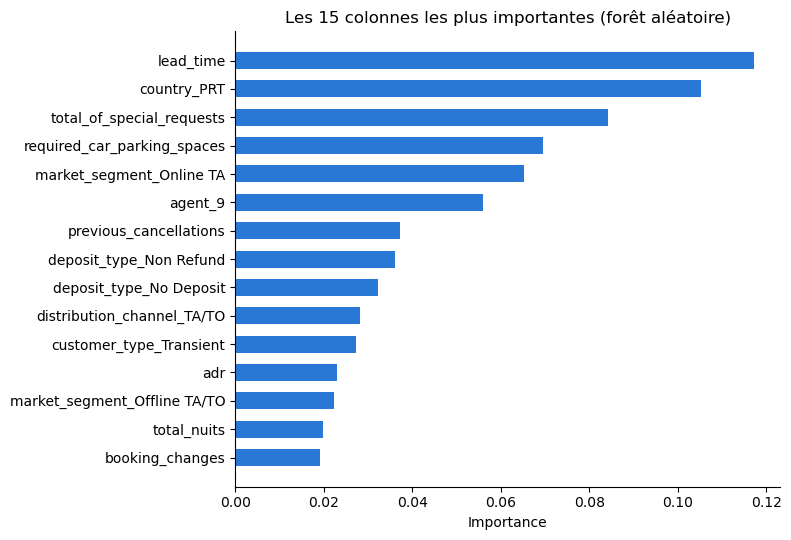

In [7]:
top = importances.head(15).sort_values("importance")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["colonne"].str.split("__").str[1], top["importance"], color="#2a78d6", height=0.6)
ax.set_title("Les 15 colonnes les plus importantes (forêt aléatoire)")
ax.set_xlabel("Importance")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "04_importance_variables.png", dpi=120)
plt.show()

**Ce qu'on observe :**

- Le graphique montre les 15 mêmes colonnes que le tableau, de la plus importante (en haut) à la moins importante.
- `lead_time` et `country_PRT` sont loin devant (plus de 0,10 chacune).
- Après les 6 premières colonnes, l'importance baisse beaucoup : 0,0560 pour la 6e, puis 0,0371 pour la 7e.

In [8]:
# L'importance ne dit pas le sens de l'effet. On regarde le taux d'annulation (train)
# pour quelques variables importantes.
train = X_train.copy()
train["is_canceled"] = y_train.values

def taux_annulation(groupes_lignes):
    return (train.groupby(groupes_lignes, observed=True)["is_canceled"].mean() * 100).round(1)

print("Taux d'annulation (%) selon le délai de réservation (lead_time, en jours) :")
print(taux_annulation(pd.cut(train["lead_time"], bins=[-1, 7, 30, 90, 180, 800])).to_string())
print()
print("Taux d'annulation (%) selon le pays :")
print(taux_annulation(np.where(train["country"] == "PRT", "Portugal", "Autre pays")).to_string())
print()
print("Taux d'annulation (%) selon le nombre de demandes spéciales :")
print(taux_annulation(train["total_of_special_requests"]).to_string())
print()
print("Taux d'annulation (%) selon la place de stationnement demandée :")
print(taux_annulation(np.where(train["required_car_parking_spaces"] > 0, "Oui", "Non")).to_string())
print()
print("Taux d'annulation (%) selon le type de dépôt :")
print(taux_annulation(train["deposit_type"]).to_string())

Taux d'annulation (%) selon le délai de réservation (lead_time, en jours) :
lead_time
(-1, 7]        8.3
(7, 30]       25.5
(30, 90]      31.9
(90, 180]     35.0
(180, 800]    40.0

Taux d'annulation (%) selon le pays :
Autre pays    23.8
Portugal      35.7

Taux d'annulation (%) selon le nombre de demandes spéciales :
total_of_special_requests
0    33.1
1    22.6
2    21.5
3    17.2
4    10.4
5     6.9

Taux d'annulation (%) selon la place de stationnement demandée :
Non    30.0
Oui     0.0

Taux d'annulation (%) selon le type de dépôt :
deposit_type
No Deposit    26.7
Non Refund    95.2
Refundable    24.1


**Ce qu'on observe :**

- **Délai de réservation :** plus on réserve tôt, plus le risque d'annulation est grand. Il passe de 8,3 % (7 jours ou moins) à 40,0 % (plus de 180 jours).
- **Pays :** les clients du Portugal annulent plus souvent (35,7 %) que les autres (23,8 %).
- **Demandes spéciales :** plus un client fait de demandes, moins il annule. On passe de 33,1 % (0 demande) à 6,9 % (5 demandes).
- **Stationnement :** aucune réservation avec une place de stationnement demandée n'est annulée (0,0 %).
- **Dépôt :** avec un dépôt non remboursable (« Non Refund »), 95,2 % des réservations sont annulées. C'est surprenant, on attendait l'inverse. Le modèle utilise quand même cette information, car elle sépare très bien les deux classes.
- Les demandes spéciales et le stationnement ont du sens pour un hôtel : ces clients préparent vraiment leur séjour.

In [9]:
# Contrôle : la sélection fait-elle perdre de l'information ?
# On compare un modèle simple avec et sans sélection (validation croisée en 3 parties, sur le train).
modele_controle = LogisticRegression(max_iter=1000)

sans_selection = Pipeline([
    ("pretraitement", pipeline_pretraitement),
    ("modele", modele_controle),
])
avec_selection = Pipeline([
    ("pretraitement", pipeline_pretraitement),
    ("selection", selecteur),
    ("modele", modele_controle),
])

for nom, pipe in [("Sans sélection", sans_selection), ("Avec sélection", avec_selection)]:
    scores = cross_val_score(pipe, X_train, y_train, cv=3, scoring="f1")
    print(f"{nom} : F1 moyen = {scores.mean():.3f}")

Sans sélection : F1 moyen = 0.613


Avec sélection : F1 moyen = 0.604


**Ce qu'on observe :**

- Avec la sélection, le F1 moyen passe de 0,613 à 0,604.
- La perte est très petite, alors que le modèle utilise 2 fois moins de colonnes (54 au lieu de 108).
- Un modèle avec moins de colonnes est plus rapide et plus facile à expliquer. Nous gardons donc la sélection.

## Sauvegarde pour le notebook 05

In [10]:
joblib.dump(pipeline_selection, DOSSIER_MODELES / "etape4_pipeline_selection.joblib", compress=3)
print("Fichier créé : modeles/etape4_pipeline_selection.joblib")

Fichier créé : modeles/etape4_pipeline_selection.joblib


**Ce qu'on observe :**

- Le pipeline « prétraitement + sélection » est sauvegardé.
- Le notebook 05 va le recharger et lui ajouter le modèle de classification.